In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from ar1_model import AR1Gaussian
from wasserstein_estimation import estimate_W, _gamma_hat

rng = np.random.default_rng(0)

### 2d grid plot

Sweeping over a grid of persistencies and sample sizes, we record a sample of the standardised statistic $\sqrt n (\hat \gamma(k) - \gamma(k)) / \sqrt{\Sigma(k)}$ and compare its histogram against the standard normal density. For each configuration, we also estimate the Wasserstein distance


In [19]:
def fit_ar1_ols(x):
    """Cheap per-path OLS refit, used for bias checks and as MLE starting values."""
    x0, x1 = x[:-1], x[1:]
    X = np.column_stack([np.ones_like(x0), x0])
    beta, *_ = np.linalg.lstsq(X, x1, rcond=None)
    resid_b = x1 - X @ beta
    return beta[1], resid_b.var(ddof=2)

In [20]:
# Parameters
n_size = 5
phi_size = 5
r = 2.0  # geometric ratio (can be any value > 1)
n_0 = 120  # base sample size
kappa = 12  # anchor constant

# Geometric sequences
ns = np.array([n_0 * (r ** i) for i in range(n_size)]).astype(int)
nus = np.array([kappa / (n_0 * (r ** j)) for j in range(phi_size)])
phis = 1 - nus  # recover phis from nus

# Compute grid
products = np.outer(ns, nus)

print("n values:", ns)
print("ν values:", nus)
print("φ values:", phis)
print("\nProducts (constant along diagonals):")
print(np.round(products, 2))

n values: [ 120  240  480  960 1920]
ν values: [0.1     0.05    0.025   0.0125  0.00625]
φ values: [0.9     0.95    0.975   0.9875  0.99375]

Products (constant along diagonals):
[[ 12.     6.     3.     1.5    0.75]
 [ 24.    12.     6.     3.     1.5 ]
 [ 48.    24.    12.     6.     3.  ]
 [ 96.    48.    24.    12.     6.  ]
 [192.    96.    48.    24.    12.  ]]


In [21]:
alphas = phis

lag = 1
R_n, B_n = 10_000, 50
confidence = 0.05
z_nom = stats.norm.ppf(1 - confidence / 2)

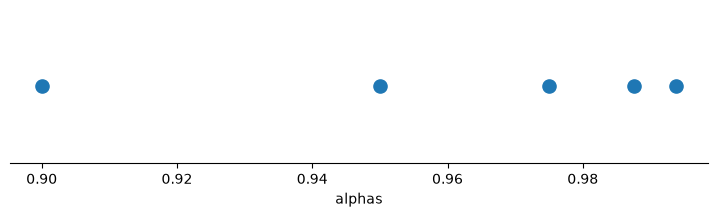

In [22]:
alphas = phis

fig, ax = plt.subplots(figsize=(9, 2))
ax.scatter(alphas, [0] * len(alphas), s=90)
ax.set_yticks([])  # hide the y-axis, it's meaningless
ax.spines[["top", "left", "right"]].set_visible(False)
ax.set_xlabel("alphas")
plt.show()

In [23]:
from tqdm import tqdm

w1_estimates, z_distributions, sim_q_cis = {}, {}, {}
z_plugin_distributions, plugin_coverage, plugin_excluded = {}, {}, {}
oracle_coverage = {}

# uses OLS estimation instead of MLE because it was too slow for this grid (R_n paths x every (n,phi)
# cell, ~40ms/fit). See the commented-out MLE block below to switch back.

total_combinations = len(ns) * len(alphas)
with tqdm(total=total_combinations, desc="Computing estimates") as pbar:
    for alpha in alphas:
        for ni in ns:
            m = AR1Gaussian(ni, alpha, kappa_2=1, k=lag)
            key = (ni, alpha)

            # --- oracle: unchanged, via the repo's own estimator ---
            w1_estimate, z_distribution = estimate_W(
                m, R=R_n, B=B_n, rng=rng, normalise=True, return_covariance_distribution=True
            )
            sim_q_cis[key] = np.quantile(z_distribution, [confidence / 2, 1 - confidence / 2])
            w1_estimates[key] = w1_estimate
            z_distributions[key] = z_distribution

            oracle_coverage[key] = np.mean(np.abs(z_distribution) <= z_nom)

            # --- plug-in: separate batch, refit (alpha, sigma2) per path ---
            gamma_true = m.gamma(lag)
            paths = m.sample_paths(R_n, rng)
            gamma_hat_r = _gamma_hat(paths, lag)

            z_plugin_list, covered_list = [], []
            n_excluded = 0
            for r, x in enumerate(paths):
                a_b, s2_b = fit_ar1_ols(x)
                if abs(a_b) >= 1:
                    n_excluded += 1
                    continue
                Sigma_hat_b = AR1Gaussian(ni, a_b, kappa_2=s2_b, k=lag).Sigma(lag)
                z_plugin_list.append(np.sqrt(ni) * (gamma_hat_r[r] - gamma_true) / np.sqrt(Sigma_hat_b))
                hw_b = z_nom * np.sqrt(Sigma_hat_b / ni)
                covered_list.append(abs(gamma_hat_r[r] - gamma_true) <= hw_b)

            # --- MLE version (slow, ~40ms/fit; uncomment to switch back, and comment out
            # the OLS block above) ---
            # z_plugin_list, covered_list = [], []
            # n_excluded = 0
            # with warnings.catch_warnings():
            #     warnings.simplefilter("ignore")
            #     for r, x in enumerate(paths):
            #         a0, s0 = fit_ar1_ols(x)  # cheap, data-driven start values
            #         try:
            #             m_b = ARIMA(x, order=(1, 0, 0), trend="c").fit(
            #                 start_params=[x.mean(), np.clip(a0, -0.98, 0.98), max(s0, 1e-8)]
            #             )
            #             a_b = m_b.arparams[0]
            #             s2_b = m_b.params[list(m_b.param_names).index("sigma2")]
            #             retvals = getattr(m_b, "mle_retvals", None) or {}
            #             converged = bool(retvals.get("converged", True)) and abs(a_b) < 1
            #         except Exception:
            #             converged = False
            #
            #         if not converged:
            #             n_excluded += 1
            #             continue
            #
            #         Sigma_hat_b = AR1Gaussian(ni, a_b, kappa_2=s2_b, k=lag).Sigma(lag)
            #         z_plugin_list.append(np.sqrt(ni) * (gamma_hat_r[r] - gamma_true) / np.sqrt(Sigma_hat_b))
            #         hw_b = z_nom * np.sqrt(Sigma_hat_b / ni)
            #         covered_list.append(abs(gamma_hat_r[r] - gamma_true) <= hw_b)

            z_plugin_distributions[key] = np.array(z_plugin_list)
            plugin_coverage[key] = np.mean(covered_list) if covered_list else np.nan
            plugin_excluded[key] = n_excluded

            pbar.update(1)

Computing estimates: 100%|██████████| 25/25 [06:00<00:00, 14.41s/it]


In [28]:
import pickle
from pathlib import Path

output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

with open(output_dir / "monte_carlo_grid_results.pkl", "wb") as f:
    pickle.dump(
        {
            "ns": ns,
            "alphas": alphas,
            "lag": lag,
            "R_n": R_n,
            "B_n": B_n,
            "confidence": confidence,
            "w1_estimates": w1_estimates,
            "z_distributions": z_distributions,
            "sim_q_cis": sim_q_cis,
            "z_plugin_distributions": z_plugin_distributions,
            "plugin_coverage": plugin_coverage,
            "plugin_excluded": plugin_excluded,
            "oracle_coverage": oracle_coverage,
        },
        f,
    )

In [ ]:
# Load pre-computed results instead of rerunning the grid above.
"""
with open(output_dir / "monte_carlo_grid_results.pkl", "rb") as f:
     _results = pickle.load(f)

ns = _results["ns"]
alphas = _results["alphas"]
lag = _results["lag"]
R_n = _results["R_n"]
B_n = _results["B_n"]
confidence = _results["confidence"]
w1_estimates = _results["w1_estimates"]
z_distributions = _results["z_distributions"]
sim_q_cis = _results["sim_q_cis"]
z_plugin_distributions = _results["z_plugin_distributions"]
plugin_coverage = _results["plugin_coverage"]
plugin_excluded = _results["plugin_excluded"]
oracle_coverage = _results["oracle_coverage"]
"""

In [30]:
fontsize = 14
XLIM = (-8, 8)


def hist_density_clipped(ax, data, bins, xrange, **kwargs):
    """Histogram visually clipped to xrange, but density normalised by the FULL
    sample size (not just the visible portion) -- so bar heights still honestly
    reflect 'fraction of all draws', rather than pretending the tail didn't happen.
    Returns the fraction of draws that fell outside xrange."""
    counts, edges = np.histogram(data, bins=bins, range=xrange)
    bin_width = edges[1] - edges[0]
    density = counts / (len(data) * bin_width)
    ax.bar(edges[:-1], density, width=bin_width, align="edge", **kwargs)
    return np.mean((data < xrange[0]) | (data > xrange[1]))

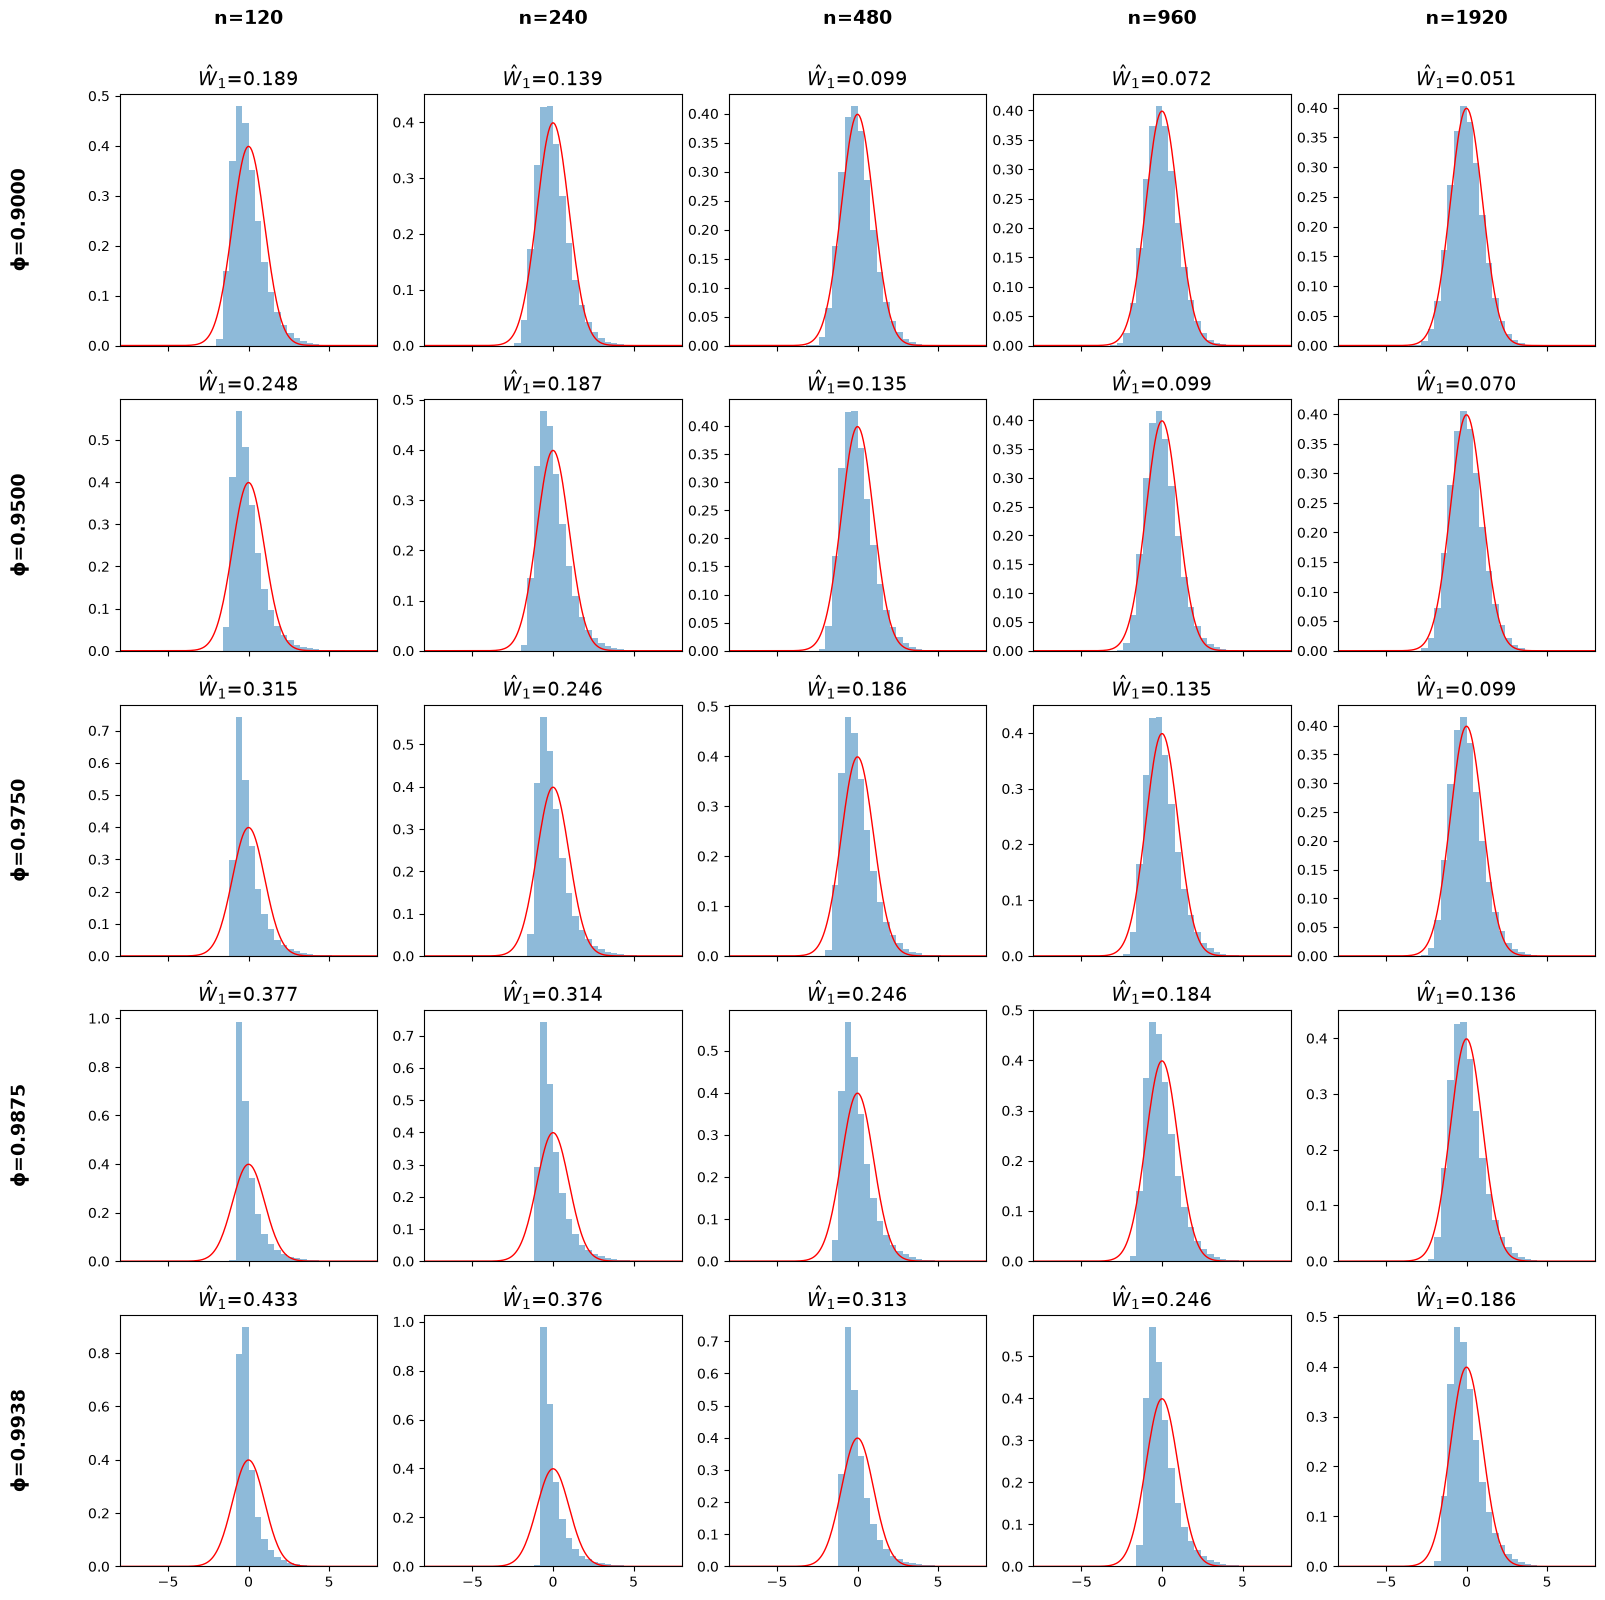

In [37]:
fig, axes = plt.subplots(
    len(alphas), len(ns), figsize=(3.2 * len(ns), 3.2 * len(alphas)), sharey=False, sharex=True
)

for i, alpha in enumerate(alphas):
    for j, ni in enumerate(ns):
        ax = axes[i, j]
        key = (ni, alpha)

        frac_out_oracle = hist_density_clipped(
            ax, z_distributions[key], bins=40, xrange=XLIM, alpha=0.5, color="tab:blue", label="oracle"
        )

        xs = np.linspace(*XLIM, 200)
        ax.plot(xs, stats.norm.pdf(xs), "r-", linewidth=1)

        """
        # Normal quantiles (±1.96)
        ax.axvline(-1.96, color="red", linestyle="dashdot", linewidth=0.8, label="Normal q. (±1.96)")
        ax.axvline(1.96, color="red", linestyle="dashdot", linewidth=0.8)

        # Empirical quantiles from finite sample
        q_lower = np.quantile(z_distributions[key], 0.025)
        q_upper = np.quantile(z_distributions[key], 0.975)
        ax.axvline(q_lower, color="black", linestyle="solid", linewidth=1.2, label="Empirical q.")
        ax.axvline(q_upper, color="black", linestyle="solid", linewidth=1.2)
        """

        ax.set_xlim(XLIM)

        excl = plugin_excluded[key]
        extra = []
        if excl > 0:
            extra.append(f"refit|α|≥1: {excl}/{R_n}")
        #subtitle = rf"$\hat W_1$={w1_estimates[key]:.3f}, cov={plugin_coverage[key]:.2f}"
        subtitle = rf"$\hat W_1$={w1_estimates[key]:.3f}"
        ax.set_title(subtitle, fontsize=fontsize)

        if i == 0:
            ax.annotate(
                f"n={ni}",
                xy=(0.5, 1.28),
                xycoords="axes fraction",
                ha="center",
                fontsize=fontsize,
                fontweight="bold",
            )

        if j == 0:
            ax.annotate(
                f"ϕ={alpha:.4f}",
                xy=(-0.35, 0.5),
                xycoords="axes fraction",
                ha="right",
                va="center",
                fontsize=fontsize,
                fontweight="bold",
                rotation=90,
            )

# Add figure-level legend
#handles, labels = axes[0, 0].get_legend_handles_labels()
#fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.02), fontsize=fontsize)

fig.tight_layout()
fig.savefig("tcu_grid.pdf")
plt.show()